# Q5: one function does everything: `auto_prepare()`
Load any file → clean → split 80/20 → find the best poly degree. It prints every step.
```python
d = auto_prepare("../exam.xlsx", target="Price")              # Q1 (regression)
d = auto_prepare("../exam.csv", target="Survived", max_degree=0)   # Q2 classification: no degree
```
You get back `d["x_train"], d["x_test"], d["y_train"], d["y_test"], d["cols"], d["degree"]`,
and `d["xp_train"], d["xp_test"]` = poly features of the best degree, ready for `linear()`.

**In the exam:** copy cell 1 (the function) into your notebook, then use it like cell 2.

## 1. The function (copy this cell)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def auto_prepare(data, target, cols=None, test_size=0.2, max_degree=6, seed=42, show=True):
    """
    ONE function: load any file -> clean -> split -> find the best poly degree.
      data   : file path (csv, txt, tsv, xlsx, json, parquet, zip) or a DataFrame
      target : y column name
      cols   : x columns to use (None = every column after cleaning)
      max_degree : 0 = skip the degree search (classification)
    returns a dict: x_train, x_test, y_train, y_test, cols, degree, xp_train, xp_test, df
      xp_train / xp_test = x, x^2 ... x^degree (scaled), ready for linear()
    """
    say = print if show else (lambda *a: None)

    # ---------- 1. LOAD ----------
    if isinstance(data, pd.DataFrame):
        df = data.copy()
    else:
        p = str(data).lower()
        if p.endswith((".xlsx", ".xls")):
            df = pd.read_excel(data)
        elif p.endswith(".json"):
            try:
                df = pd.read_json(data)
            except ValueError:
                df = pd.read_json(data, lines=True)
        elif p.endswith(".parquet"):
            df = pd.read_parquet(data)
        else:
            for enc in ["utf-8-sig", "cp874", "latin-1"]:
                try:
                    df = pd.read_csv(data, sep=None, engine="python", encoding=enc)
                    break
                except UnicodeDecodeError:
                    pass
            if all(str(c).replace(".", "").replace("-", "").isdigit() for c in df.columns):
                df = pd.read_csv(data, sep=None, engine="python", header=None, encoding=enc)
                df.columns = [f"col{i}" for i in range(df.shape[1])]
                say("no header -> columns named col0, col1 ...")
    say(f"1 load    : {df.shape[0]} rows x {df.shape[1]} cols")

    # ---------- 2. CLEAN ----------
    df.columns = [str(c).strip() for c in df.columns]
    df = df.replace(["?", "", " ", "NA", "N/A", "na", "n/a", "null", "NULL", "None", "-", "--", "missing", -999, -9999], np.nan)
    for c in df.select_dtypes(exclude="number").columns:
        t = df[c].astype(str).str.strip()
        df[c] = df[c].where(df[c].isna(), t if c == target else t.str.lower())
    n = df.duplicated().sum()
    df = df.drop_duplicates()
    say(f"2 clean   : '?', 'NA', -999 ... -> missing | {n} duplicate rows dropped")
    for c in df.select_dtypes(exclude="number").columns:
        num = pd.to_numeric(df[c].astype(str).str.replace(r"[,\s$฿€£%]", "", regex=True), errors="coerce")
        if df[c].notna().sum() and num.notna().sum() >= 0.9 * df[c].notna().sum():
            df[c] = num
            say(f"            {c}: text like '1,200' -> number")
    n = df[target].isna().sum()
    df = df[df[target].notna()]
    if n:
        say(f"            {n} rows without {target} dropped (never fill y)")
    for c in df.select_dtypes(exclude="number").columns:
        if c == target:
            continue
        s = df[c].dropna().astype(str).head(200)
        if len(s) and s.str.contains(r"\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}").mean() > 0.8:
            d = pd.to_datetime(df[c], errors="coerce", dayfirst=True)
            if d.notna().mean() > 0.8:
                df[c + "_year"], df[c + "_month"], df[c + "_day"], df[c + "_weekday"] = d.dt.year, d.dt.month, d.dt.day, d.dt.weekday
                df = df.drop(columns=c)
                say(f"            {c}: date -> year / month / day / weekday")
    rows = len(df)
    for c in list(df.columns):
        if c == target:
            continue
        nun, miss = df[c].nunique(), df[c].isna().mean()
        idname = str(c).lower().endswith(("id", "index", "_no")) or str(c).lower().startswith("unnamed")
        why = ("id column" if idname and nun > 0.9 * rows
               else "only 1 value" if nun <= 1
               else f"{miss:.0%} missing" if miss > 0.5
               else "text, all different (name)" if not pd.api.types.is_numeric_dtype(df[c]) and nun > 0.9 * rows
               else "")
        if why:
            df = df.drop(columns=c)
            say(f"            drop {c} ({why})")
    for c in df.columns:
        if c == target or not df[c].isna().any():
            continue
        if pd.api.types.is_numeric_dtype(df[c]):
            if df[c].isna().mean() >= 0.05:
                df[c + "_missing"] = df[c].isna().astype(int)
            df[c] = df[c].fillna(df[c].median())
            say(f"            {c}: fill missing with median")
        else:
            df[c] = df[c].fillna(df[c].mode()[0])
            say(f"            {c}: fill missing with most common")
    for c in df.select_dtypes(exclude="number").columns:
        if c == target:
            continue
        nun = df[c].nunique()
        if nun == 2:
            a, b = sorted(df[c].unique())
            df[c] = (df[c] == b).astype(int)
            say(f"            {c}: {a}/{b} -> 0/1")
        elif nun <= 10:
            df = pd.concat([df.drop(columns=c), pd.get_dummies(df[c], prefix=c, drop_first=True, dtype=int)], axis=1)
            say(f"            {c}: one-hot ({nun} values)")
        else:
            df[c] = df[c].map(df[c].value_counts(normalize=True))
            say(f"            {c}: frequency ({nun} values)")
    if not pd.api.types.is_numeric_dtype(df[target]):
        codes = {v: i for i, v in enumerate(sorted(df[target].unique()))}
        df[target] = df[target].map(codes)
        say(f"            target {target}: {codes}")
    say(f"            -> {df.shape[0]} rows x {df.shape[1]} cols")

    # ---------- 3. SPLIT ----------
    cols = [c for c in (cols or df.columns) if c != target]
    df = df[cols + [target]].sample(frac=1, random_state=seed)
    x, y = df[cols].values.astype(float), df[target].values.astype(float)
    n = int(len(df) * (1 - test_size))
    x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]
    say(f"3 split   : train {len(y_train)} | test {len(y_test)} | {len(cols)} x columns")
    out = dict(df=df, cols=cols, x_train=x_train, x_test=x_test, y_train=y_train, y_test=y_test, degree=None)
    if not max_degree:
        return out

    # ---------- 4. BEST POLY DEGREE (5-fold CV on train only) ----------
    mu, sd = x_train.mean(0), x_train.std(0) + 1e-9
    poly = lambda a, d: np.column_stack([np.ones(len(a))] + [((a - mu) / sd) ** p for p in range(1, d + 1)])
    fit = lambda A, b: np.linalg.pinv(A.T @ A) @ A.T @ b
    r2 = lambda a, b: 1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum()
    folds = np.array_split(np.arange(len(y_train)), 5)
    res = []
    for d in range(1, max_degree + 1):
        P = poly(x_train, d)
        cv = np.mean([r2(y_train[f], P[f] @ fit(np.delete(P, f, 0), np.delete(y_train, f))) for f in folds])
        res.append([d, r2(y_train, P @ fit(P, y_train)), cv])
    res = pd.DataFrame(res, columns=["degree", "train R2", "CV R2"])
    best = int(res.loc[res["CV R2"] >= res["CV R2"].max() - 0.01, "degree"].min())
    say(f"4 degree  : best = {best} (smallest degree within 0.01 of the top CV R2)")
    if show:
        plt.figure(figsize=(6, 3.5))
        plt.plot(res["degree"], res["train R2"], "o-", label="train R2")
        plt.plot(res["degree"], res["CV R2"], "s-", label="CV R2")
        plt.axvline(best, color="r", linestyle="--", label=f"best = {best}")
        plt.xlabel("degree"); plt.ylabel("R2"); plt.title("Poly degree: pick the top of CV R2")
        plt.legend(); plt.grid(alpha=0.3); plt.show()
        print(res.round(4).to_string(index=False))
    out.update(degree=best, degree_table=res,
               xp_train=poly(x_train, best)[:, 1:], xp_test=poly(x_test, best)[:, 1:])
    return out

## 2. Use it in Q1: your 4 models with the cleaned data and the best degree

1 load    : 891 rows x 12 cols
2 clean   : '?', 'NA', -999 ... -> missing | 0 duplicate rows dropped
            drop PassengerId (id column)
            drop Name (text, all different (name))
            drop Cabin (77% missing)
            Age: fill missing with median
            Embarked: fill missing with most common
            Sex: female/male -> 0/1
            Ticket: frequency (681 values)
            Embarked: one-hot (3 values)
            -> 891 rows x 11 cols
3 split   : train 712 | test 179 | 3 x columns
4 degree  : best = 2 (smallest degree within 0.01 of the top CV R2)


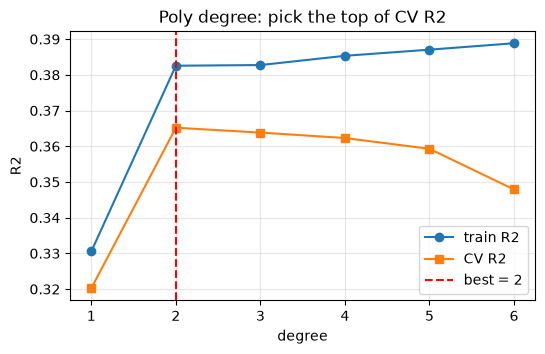

 degree  train R2  CV R2
      1    0.3305 0.3202
      2    0.3826 0.3652
      3    0.3827 0.3638
      4    0.3853 0.3623
      5    0.3870 0.3593
      6    0.3888 0.3479


,model,R2
0,Poly (degree 2),0.510050
1,Multi,0.461845
2,Linear,-0.016816


In [2]:
d = auto_prepare("../titanic.csv", target="Fare", cols=["Age", "Pclass", "SibSp"])   # <<< file, target, cols (or cols=None)
x_train, x_test, y_train, y_test = d["x_train"], d["x_test"], d["y_train"], d["y_test"]


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def r2(y_test, y_pred):
    return 1 - (((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())


preds = {
    "Linear": linear(x_train[:, :1], y_train, x_test[:, :1]),
    "Multi": linear(x_train, y_train, x_test),
    f"Poly (degree {d['degree']})": linear(d["xp_train"], y_train, d["xp_test"]),
}
rank = pd.DataFrame({"model": list(preds), "R2": [r2(y_test, p) for p in preds.values()]})
rank.sort_values("R2", ascending=False).reset_index(drop=True)

## 3. All columns (`cols=None`): the function cleans and uses every useful column

1 load    : 891 rows x 12 cols
2 clean   : '?', 'NA', -999 ... -> missing | 0 duplicate rows dropped
            drop PassengerId (id column)
            drop Name (text, all different (name))
            drop Cabin (77% missing)
            Age: fill missing with median
            Embarked: fill missing with most common
            Sex: female/male -> 0/1
            Ticket: frequency (681 values)
            Embarked: one-hot (3 values)
            -> 891 rows x 11 cols
3 split   : train 712 | test 179 | 10 x columns


4 degree  : best = 2 (smallest degree within 0.01 of the top CV R2)


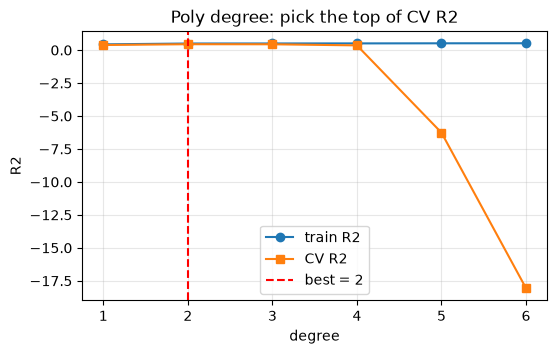

 degree  train R2    CV R2
      1    0.4340   0.3856
      2    0.4987   0.4449
      3    0.5013   0.4401
      4    0.5069   0.3568
      5    0.5141  -6.2645
      6    0.5185 -18.0649
x columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Age_missing', 'Embarked_q', 'Embarked_s']
Poly degree 2 test R2 = 0.6311


In [3]:
d = auto_prepare("../titanic.csv", target="Fare")
print("x columns:", d["cols"])
p = linear(d["xp_train"], d["y_train"], d["xp_test"])
print(f"Poly degree {d['degree']} test R2 = {r2(d['y_test'], p):.4f}")

## 4. A very dirty table (works the same with a DataFrame instead of a file)

In [4]:
rng = np.random.default_rng(0)
size = rng.integers(20, 120, 60)
price = 30 * size + 0.4 * size ** 2 + rng.normal(0, 300, 60)            # a curve -> degree 2
dirty = pd.DataFrame({
    "ID": range(1, 61),
    "Price": [f"${v:,.0f}" for v in price],                                 # "$1,234" text
    "Size": size,
    "Date": pd.date_range("2024-01-01", periods=60, freq="5D").strftime("%d/%m/%Y"),
    "City": rng.choice([" BKK", "bkk ", "CNX", "HKT", None], 60),          # spaces, case, missing
    "Sold": rng.choice(["yes", "no", None], 60),
})
dirty.loc[[3, 17], "Price"] = "?"
dirty.loc[[5, 40], "Size"] = -999
dirty = pd.concat([dirty, dirty.iloc[:3]])                                  # 3 duplicate rows
dirty.head(8)

,ID,Price,Size,Date,City,Sold
0,1,"$7,257",105,01/01/2024,NaN,NaN
1,2,"$5,183",83,06/01/2024,BKK,NaN
2,3,"$4,099",71,11/01/2024,BKK,yes
3,4,?,46,16/01/2024,NaN,no
4,5,"$2,564",50,21/01/2024,BKK,NaN
5,6,"$1,057",-999,26/01/2024,NaN,yes
6,7,$905,27,31/01/2024,NaN,yes
7,8,$768,21,05/02/2024,NaN,yes


1 load    : 63 rows x 6 cols
2 clean   : '?', 'NA', -999 ... -> missing | 3 duplicate rows dropped
            Price: text like '1,200' -> number
            2 rows without Price dropped (never fill y)


            Date: date -> year / month / day / weekday
            drop ID (id column)
            drop Date_year (only 1 value)
            Size: fill missing with median
            City: fill missing with most common
            Sold: fill missing with most common
            City: one-hot (3 values)
            Sold: no/yes -> 0/1
            -> 58 rows x 8 cols
3 split   : train 46 | test 12 | 7 x columns
4 degree  : best = 2 (smallest degree within 0.01 of the top CV R2)


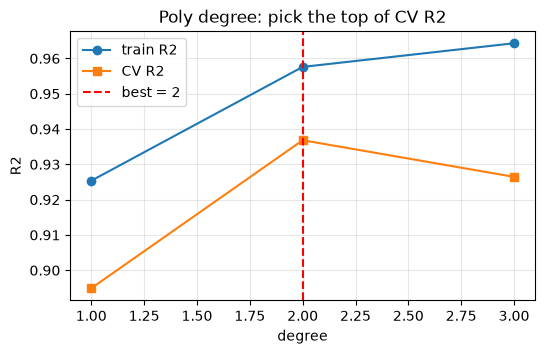

 degree  train R2  CV R2
      1    0.9254 0.8949
      2    0.9576 0.9368
      3    0.9643 0.9265


,Size,Sold,Date_month,Date_day,Date_weekday,City_cnx,City_hkt,Price
0,105.0,1,1,1,0,0,0,7257.0
6,27.0,1,1,31,2,0,0,905.0
36,28.0,1,6,29,5,0,0,1629.0
14,117.0,1,3,11,0,0,0,9065.0
46,72.0,1,8,18,6,0,0,4035.0


In [5]:
d = auto_prepare(dirty, target="Price", max_degree=3)
d["df"].head()

## 5. Q2 (classification): `max_degree=0`, then any sklearn model

In [6]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

d = auto_prepare("../titanic.csv", target="Survived", max_degree=0)
m = HistGradientBoostingClassifier(random_state=42).fit(d["x_train"], d["y_train"])
p = m.predict(d["x_test"])
print("accuracy", round(accuracy_score(d["y_test"], p), 4), "| F1", round(f1_score(d["y_test"], p), 4))

1 load    : 891 rows x 12 cols
2 clean   : '?', 'NA', -999 ... -> missing | 0 duplicate rows dropped
            drop PassengerId (id column)
            drop Name (text, all different (name))
            drop Cabin (77% missing)
            Age: fill missing with median
            Embarked: fill missing with most common
            Sex: female/male -> 0/1
            Ticket: frequency (681 values)
            Embarked: one-hot (3 values)
            -> 891 rows x 11 cols
3 split   : train 712 | test 179 | 10 x columns
accuracy 0.838 | F1 0.7717
